In [3]:
#inspect three_vs_rest dataset
import pandas as pd

df = pd.read_csv("../data/raw/four_mutations_full_data.csv.zip")

df = df[df["keep"]].copy()

print(df["three_vs_rest"].value_counts(dropna=False))

three_vs_rest
test     5743
train    2990
Name: count, dtype: int64


C:\Users\mw645\AppData\Local\Temp\ipykernel_24864\2619902338.py:4: DtypeWarning: Columns (8: one_vs_rest_validation, 10: two_vs_rest_validation, 12: three_vs_rest_validation) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/raw/four_mutations_full_data.csv.zip")


Training on HD = 0-3, testing on HD = 4

In [4]:
pd.crosstab(df["HD"], df["three_vs_rest"])

three_vs_rest,test,train
HD,,
0,0,1
1,0,27
2,0,396
3,0,2566
4,5743,0


Interesting as mutations can interact - epistasis.
Can a neural network generalise from GB1 variants with up to three mutations to variants containing four mutations?


In [5]:
train_df = df[df["three_vs_rest"] == "train"].copy()
test_df = df[df["three_vs_rest"] == "test"].copy()

print("Training variants:", len(train_df))
print("Test variants:", len(test_df))

Training variants: 2990
Test variants: 5743


In [6]:
#one hot encoding again
import numpy as np

amino_acids = "ACDEFGHIKLMNPQRSTVWY"

def one_hot_encode(sequence):
    encoding = np.zeros((4, 20))

    for position, amino_acid in enumerate(sequence):
        aa_index = amino_acids.index(amino_acid)
        encoding[position, aa_index] = 1

    return encoding.flatten()

In [7]:
# apply one-hot encoding to GB1 sequences
X_train = np.array([one_hot_encode(seq) for seq in train_df["Variants"]])
X_test = np.array([one_hot_encode(seq) for seq in test_df["Variants"]])

y_train = train_df["Fitness"].to_numpy()
y_test = test_df["Fitness"].to_numpy()

print("Training inputs:", X_train.shape)
print("Test inputs:", X_test.shape)
print("Training fitness values:", y_train.shape)
print("Test fitness values:", y_test.shape)

Training inputs: (2990, 80)
Test inputs: (5743, 80)
Training fitness values: (2990,)
Test fitness values: (5743,)


In [8]:
#Start with Ridge regression again - train here
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train, y_train)

print("Ridge regression trained!")

Ridge regression trained!


In [10]:
# evaluate
from sklearn.metrics import mean_squared_error
from scipy.stats import spearmanr

ridge_predictions = ridge_model.predict(X_test)

ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
ridge_spearman = spearmanr(y_test, ridge_predictions).statistic

print("Ridge RMSE:", round(ridge_rmse, 3))
print("Ridge Spearman:", round(ridge_spearman, 3))

Ridge RMSE: 1.012
Ridge Spearman: 0.755


Interesting - Ridge regression performs worse on new mutation-distance split.
RMSE 0.855 to 1.012 and Spearman 0.788 to 0.755
However, must note also training on fewer examples (2990 vs 6988)
Now, can neural network outperform here?

In [11]:
# prepare PyTorch data - convert numpy arrays into tensors 
import torch
import torch.nn as nn

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

print("Training tensor:", X_train_tensor.shape)
print("Test tensor:", X_test_tensor.shape)

Training tensor: torch.Size([2990, 80])
Test tensor: torch.Size([5743, 80])


Now need to prepare neural network and perform validation again - divide 2,990 training variants into 80-20 split

In [12]:
#generate validation split
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

print("Training subset:", X_fit.shape)
print("Validation subset:", X_val.shape)

Training subset: (2392, 80)
Validation subset: (598, 80)


In [13]:
#convert validation split into PyTorch tensors
X_fit_tensor = torch.tensor(X_fit, dtype=torch.float32)
y_fit_tensor = torch.tensor(y_fit, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

print("Training:", X_fit_tensor.shape)
print("Validation:", X_val_tensor.shape)

Training: torch.Size([2392, 80])
Validation: torch.Size([598, 80])


In [ ]:
# Build neural network
torch.manual_seed(42)

model_val = nn.Sequential(
    nn.Linear(80, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
# 80 (4x20) one-hot encoded AA features produces 32 learned features. 
loss_fn = nn.MSELoss()

optimizer = torch.optim.Adam(
    model_val.parameters(),
    lr=0.001
)

In [15]:
#now train with early stopping
import copy

best_val_loss = float("inf")
best_epoch = 0
best_model_weights = None

patience = 100
epochs_without_improvement = 0

train_losses = []
val_losses = []

for epoch in range(1, 2001):
    model_val.train()

    predictions = model_val(X_fit_tensor).squeeze(1)
    train_loss = loss_fn(predictions, y_fit_tensor)

    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    model_val.eval()
    with torch.no_grad():
        val_predictions = model_val(X_val_tensor).squeeze(1)
        val_loss = loss_fn(val_predictions, y_val_tensor)

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_epoch = epoch
        best_model_weights = copy.deepcopy(model_val.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch % 200 == 0:
        print(f"Epoch {epoch}: Validation loss = {val_loss.item():.4f}")

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch}")
        break

print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))

Epoch 200: Validation loss = 0.6522
Epoch 400: Validation loss = 0.5190
Epoch 600: Validation loss = 0.3887
Epoch 800: Validation loss = 0.3066
Epoch 1000: Validation loss = 0.2754
Epoch 1200: Validation loss = 0.2553
Epoch 1400: Validation loss = 0.2479
Epoch 1600: Validation loss = 0.2438
Epoch 1800: Validation loss = 0.2399
Early stopping at epoch 1847
Best epoch: 1747
Best validation loss: 0.2396


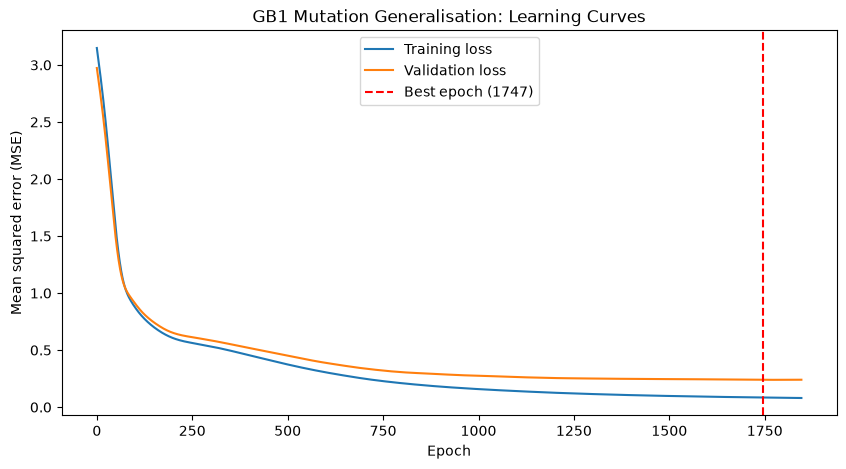

In [16]:
#Plot training and validation loss
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")

plt.axvline(
    best_epoch - 1,
    color="red",
    linestyle="--",
    label=f"Best epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Mean squared error (MSE)")
plt.title("GB1 Mutation Generalisation: Learning Curves")
plt.legend()
plt.show()

Validation loss at lowest at epoch 1747. Validation loss and training loss gradually separate - suggests the network is becoming increasingly specialised to its training examples, while improvements on unseen validation variants are becoming very small.

In [17]:
#create final neural network
torch.manual_seed(42)

model_final = nn.Sequential(
    nn.Linear(80, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)

optimizer_final = torch.optim.Adam(
    model_final.parameters(),
    lr=0.001
)

In [18]:
# train final model
final_losses = []

for epoch in range(best_epoch):
    model_final.train()

    predictions = model_final(X_train_tensor).squeeze(1)
    loss = loss_fn(predictions, y_train_tensor)

    optimizer_final.zero_grad()
    loss.backward()
    optimizer_final.step()

    final_losses.append(loss.item())

    if (epoch + 1) % 300 == 0:
        print(f"Epoch {epoch + 1}: Training loss = {loss.item():.4f}")

print("Final training loss:", round(final_losses[-1], 4))

Epoch 300: Training loss = 0.5380
Epoch 600: Training loss = 0.3151
Epoch 900: Training loss = 0.1933
Epoch 1200: Training loss = 0.1355
Epoch 1500: Training loss = 0.1048
Final training loss: 0.0915


In [19]:
# evaluate with test data
model_final.eval()

with torch.no_grad():
    nn_predictions = model_final(X_test_tensor).squeeze(1).numpy()

nn_rmse = np.sqrt(mean_squared_error(y_test, nn_predictions))
nn_spearman = spearmanr(y_test, nn_predictions).statistic

print("Neural network RMSE:", round(nn_rmse, 3))
print("Neural network Spearman:", round(nn_spearman, 3))

Neural network RMSE: 0.849
Neural network Spearman: 0.808


Neural network outperforms Ridge regression - 16% lower RMSE and higher Spearman correlation. 
One possible explanation is that the network can capture nonlinear interactions between amino acids, which Ridge regression cannot explicitly represent.
However, neural network RMSE increased substantially when we moved to the mutation - distance split - suggests task is harder for mutation - split distance.
Remember, fewer training variants were used.

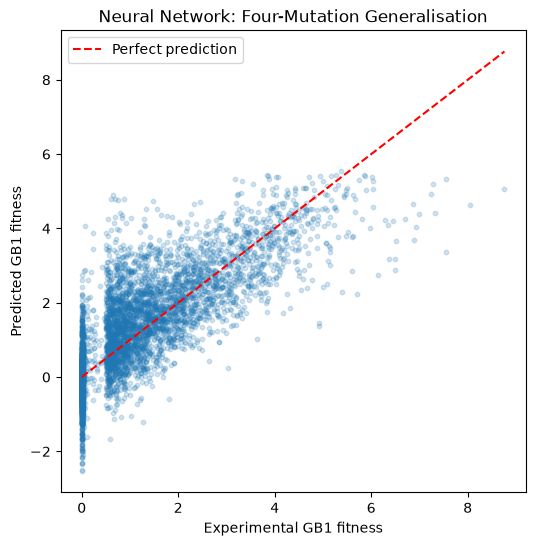

In [20]:
#visualise
plt.figure(figsize=(6, 6))

plt.scatter(y_test, nn_predictions, alpha=0.2, s=10)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Experimental GB1 fitness")
plt.ylabel("Predicted GB1 fitness")
plt.title("Neural Network: Four-Mutation Generalisation")
plt.legend()
plt.show()

In [ ]:
#clipped limits fitness to positive values
clipped_predictions = np.maximum(nn_predictions, 0)

clipped_rmse = np.sqrt(
    mean_squared_error(y_test, clipped_predictions)
)

print("Original RMSE:", round(nn_rmse, 3))
print("Clipped RMSE:", round(clipped_rmse, 3))

Original RMSE: 0.849
Clipped RMSE: 0.79


In [22]:
clipped_spearman = spearmanr(y_test, clipped_predictions).statistic

print("Original Spearman:", round(nn_spearman, 3))
print("Clipped Spearman:", round(clipped_spearman, 3))

Original Spearman: 0.808
Clipped Spearman: 0.813


Neural network reproducibility across random seeds

In [23]:
seeds = [42, 123, 456, 789, 2026]

results = []